# **Step3 -> "Pre-procesamiento: Limpieza de datos"**

##wd

In [ ]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pwd

/content


In [ ]:
working_dir = "/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 3"
%cd $working_dir

/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 3


In [ ]:
!pwd

/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 3


In [ ]:
import pandas as pd

## Archivo de datos: **datos_censo.csv**


In [ ]:
datos = pd.read_csv("datos_censo.csv", sep=";")
print(datos.shape)
datos.head()

(32560, 14)


,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k,awards
0,1,39.0,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,40.0,United-States,0,NaN
1,2,50.0,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,13.0,United-States,0,NaN
2,3,38.0,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,40.0,United-States,0,NaN
3,4,53.0,Private,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40.0,United-States,0,NaN
4,5,28.0,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40.0,Cuba,0,NaN


In [ ]:
# Omitimos duplicados
print(datos.shape)
datos.drop_duplicates(inplace=True)
print(datos.shape)

(32560, 14)
(32560, 14)


In [ ]:
datos.dtypes

,0
id,int64
age,float64
workclass,object
education,object
education_num,float64
marital_status,object
occupation,object
relationship,object
race,object
gender,object


In [ ]:
datos.dtypes

,0
id,int64
age,float64
workclass,object
education,object
education_num,float64
marital_status,object
occupation,object
relationship,object
race,object
gender,object


In [ ]:
# string != objecto != categorical
datos[['id', 'workclass',	'education', 'marital_status',	'occupation',
       'relationship',	'race',	'gender', 'native_country',	'greater_than_50k']] = datos[['id', 'workclass',	'education', 'marital_status',	'occupation',
                                                                                         'relationship',	'race',	'gender', 'native_country',	'greater_than_50k']].astype('string')
datos.dtypes

,0
id,string[python]
age,float64
workclass,string[python]
education,string[python]
education_num,float64
marital_status,string[python]
occupation,string[python]
relationship,string[python]
race,string[python]
gender,string[python]


In [ ]:
print(datos.shape)
datos.drop(['awards'], axis=1, inplace=True) # Columna de flags
print(datos.shape)

(32560, 14)
(32560, 13)


In [ ]:
# Verificamos
vacios = pd.DataFrame(datos.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datos.shape[0], 2)*100
vacios

,vacios,vacios%
id,0,0.0
education,0,0.0
relationship,0,0.0
marital_status,0,0.0
gender,0,0.0
greater_than_50k,0,0.0
race,0,0.0
hours_per_week,267,1.0
education_num,466,1.0
native_country,583,2.0


## **Tratamiento de Datos Atípicos**

Primero se limpia el ruido que son atipicos para luego hacer imputaciones en los datos perdidos

### Respecto a Límite Superior

In [ ]:
datos.describe()

,age,education_num,hours_per_week
count,31961.000000,32094.000000,32293.000000
mean,38.584806,10.089705,40.457468
std,13.637531,2.572749,12.344580
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,48.000000,12.000000,45.000000
max,90.000000,16.000000,99.000000


Por teoría:

RIC: Rango Intercuartil = P75 - P25

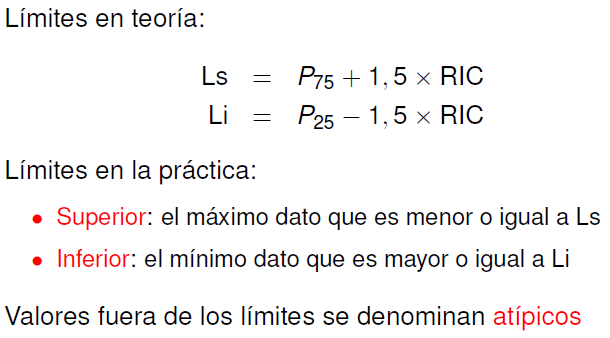

In [ ]:
import numpy as np

descriptivesMax = datos.describe(percentiles = list(np.arange(0, 1, 0.05)))
descriptivesMax # Hay datos que nos hacen ruido: max	90.000000	16.000000	99.000000

,age,education_num,hours_per_week
count,31961.000000,32094.000000,32293.000000
mean,38.584806,10.089705,40.457468
std,13.637531,2.572749,12.344580
min,17.000000,1.000000,1.000000
0%,17.000000,1.000000,1.000000
5%,19.000000,5.000000,18.000000
10%,22.000000,7.000000,24.000000
15%,24.000000,9.000000,30.000000
20%,26.000000,9.000000,35.000000
25%,28.000000,9.000000,40.000000


In [ ]:
descriptivesMax.loc['max'] > (descriptivesMax.loc['75%'] + (1.5* (descriptivesMax.loc['75%']-descriptivesMax.loc['25%']) ) )

,0
age,True
education_num,False
hours_per_week,True


In [ ]:
RIC = (descriptivesMax.loc['75%']-descriptivesMax.loc['25%'])
RIC

,0
age,20.0
education_num,3.0
hours_per_week,5.0


In [ ]:
descriptivesMax.loc['max'] > (descriptivesMax.loc['75%'] + (1.5*RIC) )

,0
age,True
education_num,False
hours_per_week,True


In [ ]:
# Límite superior de la variable Edad
descriptivesMax['age'].loc['75%'] + (1.5*RIC['age']) # Solo nos interesa el cuartil 3

np.float64(78.0)

In [ ]:
(datos[ datos['age'] > descriptivesMax['age'].loc['75%'] + (1.5*RIC['age']) ]) # Sí tiene sentido que una persona tenga 79 años asi que se acepta como valor y se hace un umbral con 3 y no con 1.5, pero con el 3 ya tenemos 99.7%; no siempre se corta segun el atipico teorico

,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
74,75,79.0,Private,Some-college,10.0,Married-civ-spouse,Prof-specialty,Other-relative,White,Male,20.0,United-States,0
222,223,90.0,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,Black,Male,40.0,United-States,0
430,431,80.0,<NA>,HS-grad,9.0,Widowed,<NA>,Not-in-family,White,Male,24.0,United-States,0
918,919,81.0,Self-emp-not-inc,HS-grad,9.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,30.0,United-States,0
1040,1041,90.0,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,White,Female,40.0,United-States,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32276,32277,90.0,Private,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,25.0,United-States,0
32366,32367,90.0,Local-gov,7th-8th,4.0,Married-civ-spouse,Protective-serv,Husband,White,Male,40.0,United-States,0
32458,32459,85.0,Private,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,3.0,Poland,0
32493,32494,82.0,<NA>,HS-grad,9.0,Never-married,<NA>,Not-in-family,White,Male,3.0,United-States,0


### Respecto a Límite Inferior

Por teoría:

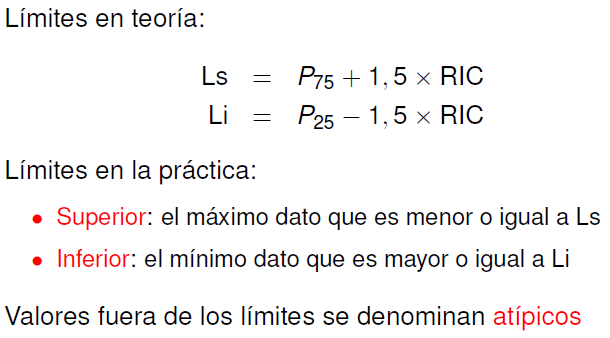

In [ ]:
descriptivesMin = datos.describe(percentiles = list( np.arange(0, 1, 0.05)) )
descriptivesMin # El minimo es el 0% asi que comparo con el 5%

,age,education_num,hours_per_week
count,31961.000000,32094.000000,32293.000000
mean,38.584806,10.089705,40.457468
std,13.637531,2.572749,12.344580
min,17.000000,1.000000,1.000000
0%,17.000000,1.000000,1.000000
5%,19.000000,5.000000,18.000000
10%,22.000000,7.000000,24.000000
15%,24.000000,9.000000,30.000000
20%,26.000000,9.000000,35.000000
25%,28.000000,9.000000,40.000000


In [ ]:
descriptivesMin.loc['min'] < ( descriptivesMin.loc['25%'] - (1.5*RIC) ) # True: Se ha encontrado al menos un atipico

,0
age,False
education_num,True
hours_per_week,True


In [ ]:
descriptivesMin['education_num'].loc['25%'] - (1.5*RIC['education_num'])

np.float64(4.5)

In [ ]:
(datos[ datos['education_num'] < descriptivesMin['education_num'].loc['25%'] - (1.5*RIC['education_num']) ])

,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
15,16,34.0,Private,7th-8th,4.0,Married-civ-spouse,Transport-moving,Husband,Amer-Indian-Eskimo,Male,45.0,Mexico,0
56,57,46.0,Private,5th-6th,3.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40.0,Mexico,0
61,62,32.0,<NA>,7th-8th,4.0,Married-spouse-absent,<NA>,Not-in-family,White,Male,40.0,<NA>,0
79,80,31.0,Local-gov,7th-8th,4.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,40.0,United-States,0
160,161,68.0,<NA>,1st-4th,2.0,Divorced,<NA>,Not-in-family,White,Female,20.0,United-States,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32430,32431,51.0,Private,7th-8th,4.0,Divorced,Machine-op-inspct,Not-in-family,White,Female,48.0,United-States,0
32431,32432,36.0,Private,Preschool,1.0,Divorced,Other-service,Not-in-family,Other,Male,72.0,Mexico,0
32447,32448,61.0,Private,7th-8th,4.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
32478,32479,64.0,State-gov,7th-8th,4.0,Married-civ-spouse,Other-service,Wife,Black,Female,40.0,United-States,0


In [ ]:
print(datos.shape)  # (#filas, #columnas)
datos.describe()    # descripción de las variables numéricas

(32560, 13)


,age,education_num,hours_per_week
count,31961.000000,32094.000000,32293.000000
mean,38.584806,10.089705,40.457468
std,13.637531,2.572749,12.344580
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,48.000000,12.000000,45.000000
max,90.000000,16.000000,99.000000


### Separamos Outliers

In [ ]:
data_sinOutlier = {}
data_Outliers = {}   #

In [ ]:
for columna in datos[['age', 'education_num', 'hours_per_week']].columns:
  data_Outliers = pd.concat([pd.DataFrame(data_Outliers),
                               datos[ (datos[columna] < (descriptivesMin[columna].loc['25%'] - (1.5*RIC[columna]))) |
                                                                (datos[columna] > (descriptivesMax[columna].loc['75%'] + (1.5*RIC[columna]))) ] ],
                              ignore_index=True)
  print(data_Outliers.shape) # No tiene sentido que el 31% de los datos sean atipicos, por lo que los umbrales en edad estan muy altos

(142, 13)
(1316, 13)
(10242, 13)


In [ ]:
print(datos.shape)
print(data_Outliers.shape)
print(10242/32560 * 100, "%")
data_Outliers # Lo mejor es hacer un tratamiento diferenciado por cada columna

(32560, 13)
(10242, 13)
31.455773955773957 %


,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
0,75,79.0,Private,Some-college,10.0,Married-civ-spouse,Prof-specialty,Other-relative,White,Male,20.0,United-States,0
1,223,90.0,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,Black,Male,40.0,United-States,0
2,431,80.0,<NA>,HS-grad,9.0,Widowed,<NA>,Not-in-family,White,Male,24.0,United-States,0
3,919,81.0,Self-emp-not-inc,HS-grad,9.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,30.0,United-States,0
4,1041,90.0,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,White,Female,40.0,United-States,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10237,32544,31.0,Private,Masters,14.0,Divorced,Other-service,Not-in-family,Other,Female,30.0,United-States,0
10238,32545,39.0,Local-gov,Assoc-acdm,12.0,Married-civ-spouse,Adm-clerical,Wife,White,Female,20.0,United-States,1
10239,32548,65.0,Self-emp-not-inc,Prof-school,15.0,Never-married,Prof-specialty,Not-in-family,White,Male,60.0,United-States,0
10240,32553,32.0,Private,Masters,14.0,Never-married,Tech-support,Not-in-family,Asian-Pac-Islander,Male,11.0,Taiwan,0


In [ ]:
data_sinOutlier = datos.drop(data_Outliers.index, axis=0)

print(datos.shape)
print(data_sinOutlier.shape)
print(22318/32560 * 100, "%")
data_sinOutlier

(32560, 13)
(22318, 13)
68.54422604422604 %


,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
10242,10243,41.0,Private,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10243,10244,42.0,Self-emp-not-inc,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10244,10245,20.0,Private,Some-college,10.0,Never-married,Sales,Not-in-family,White,Female,30.0,United-States,0
10245,10246,54.0,Private,9th,5.0,Separated,Craft-repair,Unmarried,White,Male,40.0,United-States,0
10246,10247,55.0,Private,Bachelors,13.0,Married-spouse-absent,Craft-repair,Unmarried,White,Female,55.0,Ireland,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32555,32556,27.0,Private,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,38.0,United-States,0
32556,32557,40.0,Private,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40.0,United-States,1
32557,32558,58.0,Private,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,40.0,United-States,0
32558,32559,22.0,Private,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,Male,20.0,United-States,0


In [ ]:
descriptivesMin.columns

Index(['age', 'education_num', 'hours_per_week'], dtype='object')

In [ ]:
outliers_min_values = {}
for columna in descriptivesMin.columns:
  outliers_min_values[columna] = (descriptivesMin[columna].loc['25%'] - (1.5*RIC[columna]))
print(outliers_min_values) # No tiene sentido edad -2; se tiene que ajustar a los valores real

{'age': np.float64(-2.0), 'education_num': np.float64(4.5), 'hours_per_week': np.float64(32.5)}


In [ ]:
outliers_max_values = {}
for columna in descriptivesMax.columns:
  outliers_max_values[columna] = (descriptivesMax[columna].loc['75%'] + (1.5*RIC[columna]))
print(outliers_max_values)

{'age': np.float64(78.0), 'education_num': np.float64(16.5), 'hours_per_week': np.float64(52.5)}


In [ ]:
# Guardamos los L.I. y L.S. considerados: Para que en el futuro, cuando quieras hacer prediccion, limpio mis datos para hacer cortes y usar el modelo
from pickle import dump
dump(outliers_min_values, open('outliers_min_values.pkl', 'wb')) # Se guarda archivos para luego correr un pipeline completo
dump(outliers_max_values, open('outliers_max_values.pkl', 'wb'))# Tmb se puede usar para guardar parametros de modelos

In [ ]:
print(data_Outliers.shape)
print(data_sinOutlier.shape)

(10242, 13)
(22318, 13)


### Operaciones con cadenas: para atípicos (errores) en variables categóricas

In [ ]:
data_sinOutlier.head(3)

,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
10242,10243,41.0,Private,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10243,10244,42.0,Self-emp-not-inc,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10244,10245,20.0,Private,Some-college,10.0,Never-married,Sales,Not-in-family,White,Female,30.0,United-States,0


In [ ]:
# Leer los 5 primeros casos
data_sinOutlier['gender'][0:5]

,gender
10242,Male
10243,Male
10244,Female
10245,Male
10246,Female


In [ ]:
# Cuantificar la cantidad de caracteres de cada elemento
data_sinOutlier['native_country'][0:5].str.len()

,native_country
10242,14
10243,14
10244,14
10245,14
10246,8


In [ ]:
# Convertir a mayúsculas
data_sinOutlier['native_country'][0:5].str.upper()

,native_country
10242,UNITED-STATES
10243,UNITED-STATES
10244,UNITED-STATES
10245,UNITED-STATES
10246,IRELAND


In [ ]:
# Convertir a minúsculas
data_sinOutlier['native_country'][0:5].str.lower()

,native_country
10242,united-states
10243,united-states
10244,united-states
10245,united-states
10246,ireland


In [ ]:
# Reemplazar
data_sinOutlier['native_country'][0:5].str.replace('United-States', 'Peru') # Si tengo una categoria rara, uso el replace para ya no tener problemas con atipicos categoricos

,native_country
10242,Peru
10243,Peru
10244,Peru
10245,Peru
10246,Ireland


## **Tratamiento de Datos Perdidos (vacios)**

### Contabilizamos vacíos

In [ ]:
# Contabilizamos vacíos
vacios = pd.DataFrame(data_sinOutlier.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/data_sinOutlier.shape[0], 2)*100
vacios

,vacios,vacios%
id,0,0.0
education,0,0.0
relationship,0,0.0
marital_status,0,0.0
gender,0,0.0
greater_than_50k,0,0.0
race,0,0.0
hours_per_week,240,1.0
education_num,289,1.0
native_country,397,2.0


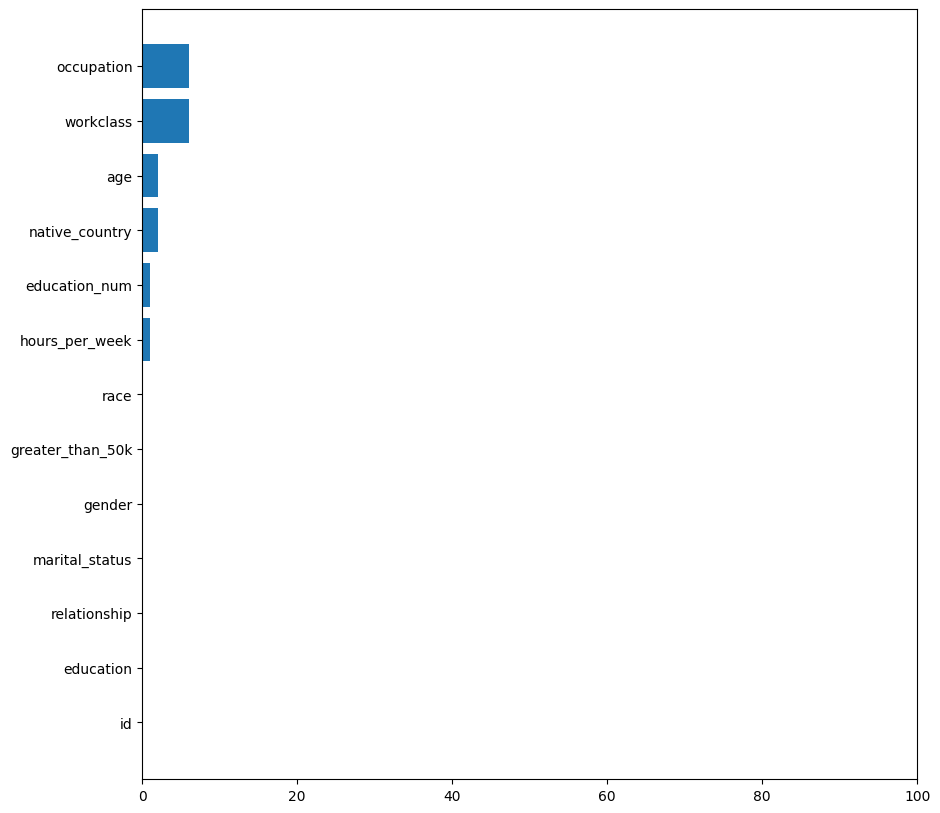

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10,10))
vac = np.arange(len(vacios['vacios%']))
plt.barh(vac, vacios['vacios%'])
plt.yticks(vac, vacios.index)
plt.xlim([0, 100])
plt.show()

In [ ]:
# Identificamos los valores perdidos.
data_sinOutlier['occupation'].isnull()

,occupation
10242,False
10243,False
10244,False
10245,False
10246,False
...,...
32555,False
32556,False
32557,False
32558,False


In [ ]:
# Identificamos los valores no perdidos.
data_sinOutlier['workclass'].notnull()

,workclass
10242,True
10243,True
10244,True
10245,True
10246,True
...,...
32555,True
32556,True
32557,True
32558,True


In [ ]:
# Cuantificamos los valores perdidos.
data_sinOutlier['native_country'].isnull().value_counts()

,count
native_country,
False,21921
True,397


In [ ]:
# Cuantificamos los valores no perdidos.
data_sinOutlier['education_num'].notnull().value_counts()

,count
education_num,
True,22029
False,289


In [ ]:
# Eliminamos los valores perdidos.
data_sinOutlier['education_num'].dropna()

,education_num
10242,10.0
10243,10.0
10244,10.0
10245,5.0
10246,13.0
...,...
32555,12.0
32556,9.0
32557,9.0
32558,9.0


In [ ]:
# Si deseamos eliminar a cualquier registro que tenga por lo menos un campo con valor perdido -> datos.dropna(axis=0, how='any', inplace=True)
#print(datos.shape)
#datos.dropna(axis=0, how='any', inplace=True)
#print(datos.shape)

### Imputación de Valores Perdidos en variables **Numéricas**

In [ ]:
#df = pd.DataFrame(np.random.randn(5, 3), index=['a0', 'a10','a20', 'a30', 'a40'],columns=['X', 'Y', 'Z'])
#df
#df2 = df.reindex(['a0', 'a1', 'a10', 'a11', 'a20', 'a21','a30', 'a31', 'a40', 'a41'])
#df2

#### Imputación de valores perdidos con ceros

/tmp/ipykernel_3856/1202620448.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plot = sns.distplot(data_sinOutlier["age"])


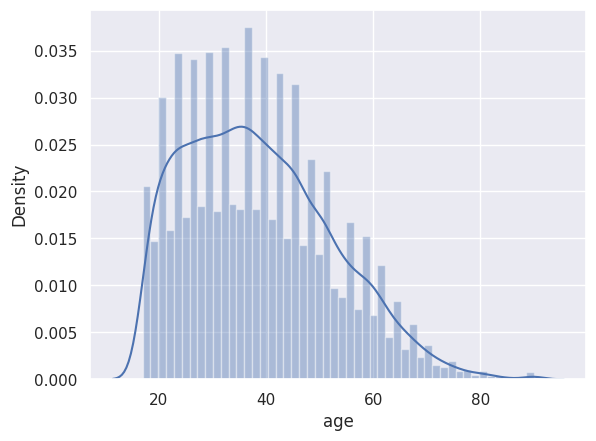

In [ ]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
plot = sns.distplot(data_sinOutlier["age"])
#plot.axvline(data_sinOutlier.M500_L.mean())
plt.show()

In [ ]:
df3 = data_sinOutlier[['age', 'education_num', 'hours_per_week']].fillna(0)
df3

,age,education_num,hours_per_week
10242,41.0,10.0,40.0
10243,42.0,10.0,40.0
10244,20.0,10.0,30.0
10245,54.0,5.0,40.0
10246,55.0,13.0,55.0
...,...,...,...
32555,27.0,12.0,38.0
32556,40.0,9.0,40.0
32557,58.0,9.0,40.0
32558,22.0,9.0,20.0


/tmp/ipykernel_3856/2056078528.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plot = sns.distplot(df3["age"])


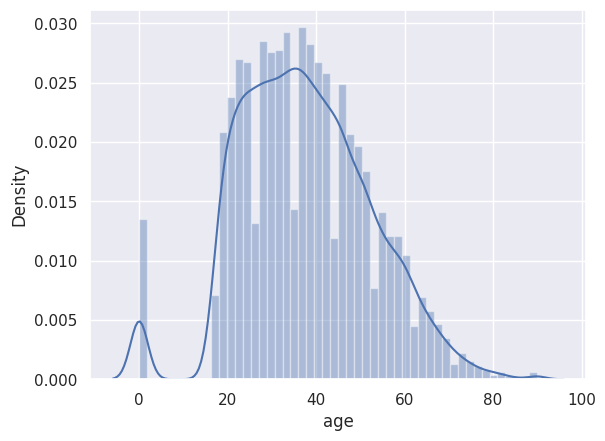

In [ ]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
plot = sns.distplot(df3["age"])
#plot.axvline(data_sinOutlier.M500_L.mean())
plt.show()

#### Imputación de valores perdidos con el Método “forward propagation”.

Se completa con los inmediatamente siguientes

Los vacíos se completan con el valor previo o posterior al nulo.

*   pad / ffill: propagate last valid observation forward to next valid
*   backfill / bfill: use next valid observation to fill gap


In [ ]:
df4 = data_sinOutlier.fillna(method='backfill')
df4

/tmp/ipykernel_3856/1702201849.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df4 = data_sinOutlier.fillna(method='backfill')


,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
10242,10243,41.0,Private,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10243,10244,42.0,Self-emp-not-inc,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,40.0,United-States,0
10244,10245,20.0,Private,Some-college,10.0,Never-married,Sales,Not-in-family,White,Female,30.0,United-States,0
10245,10246,54.0,Private,9th,5.0,Separated,Craft-repair,Unmarried,White,Male,40.0,United-States,0
10246,10247,55.0,Private,Bachelors,13.0,Married-spouse-absent,Craft-repair,Unmarried,White,Female,55.0,Ireland,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32555,32556,27.0,Private,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,38.0,United-States,0
32556,32557,40.0,Private,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40.0,United-States,1
32557,32558,58.0,Private,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,40.0,United-States,0
32558,32559,22.0,Private,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,Male,20.0,United-States,0


/tmp/ipykernel_3856/1106548013.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df4["age"])
/tmp/ipykernel_3856/1106548013.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_sinOutlier["age"], color="green", label="Marginal", kde=True)


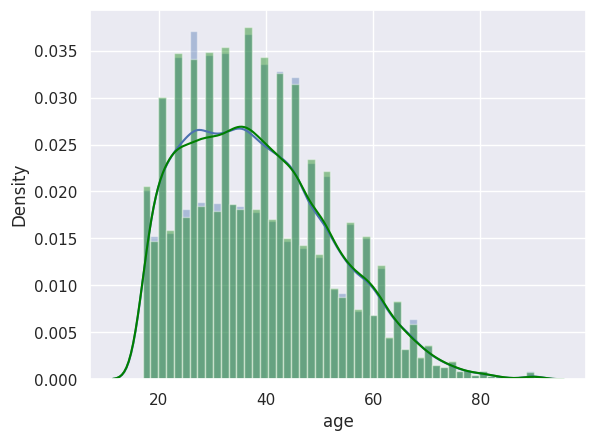

In [ ]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.distplot(df4["age"])
sns.distplot(data_sinOutlier["age"], color="green", label="Marginal", kde=True)

plt.show()

#### Imputación de valores perdidos con la MEDIA de la variable.

In [ ]:
df5 = data_sinOutlier.select_dtypes(include='number').fillna(data_sinOutlier.select_dtypes(include='number').mean())
df5

,age,education_num,hours_per_week
10242,41.0,10.0,40.0
10243,42.0,10.0,40.0
10244,20.0,10.0,30.0
10245,54.0,5.0,40.0
10246,55.0,13.0,55.0
...,...,...,...
32555,27.0,12.0,38.0
32556,40.0,9.0,40.0
32557,58.0,9.0,40.0
32558,22.0,9.0,20.0


/tmp/ipykernel_3856/239956861.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df5["age"])
/tmp/ipykernel_3856/239956861.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_sinOutlier["age"], color="green", label="Marginal", kde=True)


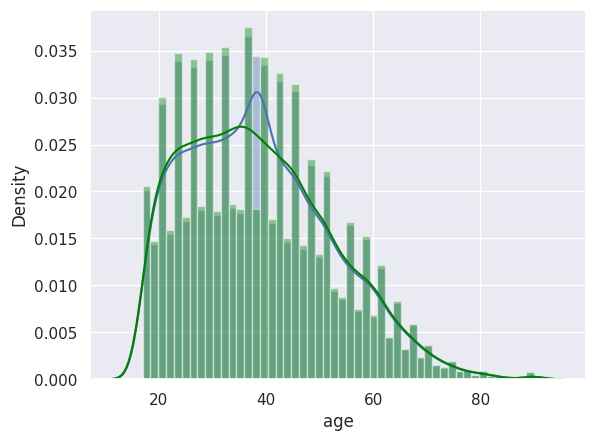

In [ ]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.distplot(df5["age"])
sns.distplot(data_sinOutlier["age"], color="green", label="Marginal", kde=True)

plt.show()

#### Imputación de valores perdidos con la MEDIANA de la variable.

In [ ]:
df52 = data_sinOutlier.select_dtypes(include='number').fillna(data_sinOutlier.select_dtypes(include='number').median())
df52

,age,education_num,hours_per_week
10242,41.0,10.0,40.0
10243,42.0,10.0,40.0
10244,20.0,10.0,30.0
10245,54.0,5.0,40.0
10246,55.0,13.0,55.0
...,...,...,...
32555,27.0,12.0,38.0
32556,40.0,9.0,40.0
32557,58.0,9.0,40.0
32558,22.0,9.0,20.0


/tmp/ipykernel_3856/2794348661.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df5["age"])
/tmp/ipykernel_3856/2794348661.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df52["age"], color="green")
/tmp/ipykernel_3856/2794348661.py:8: UserWarning: 

`distplot` is a deprecated function an

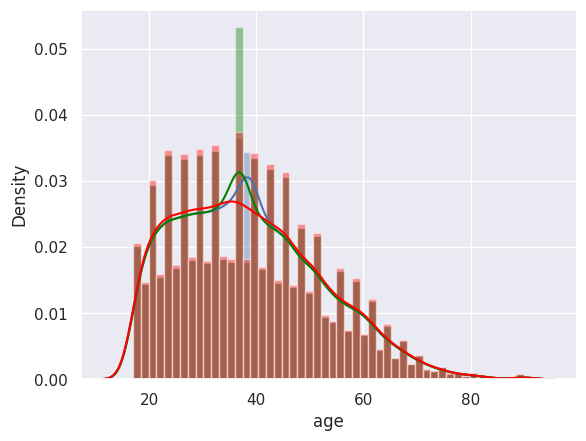

In [ ]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.distplot(df5["age"])
sns.distplot(df52["age"], color="green")
sns.distplot(data_sinOutlier["age"], color="red", label="Marginal", kde=True)

plt.show()

#### Imputación de vacíos mediante modelado de variables: **KNNImputer**

Imputacion multivariada

In [ ]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5, weights="uniform")

In [ ]:
imputer.fit(data_sinOutlier[['hours_per_week', 'education_num', 'age']])
datos[['hours_per_week', 'education_num', 'age']] = imputer.transform(datos[['hours_per_week', 'education_num', 'age']])

In [ ]:
#Contabilizamos vacíos
vacios = pd.DataFrame(datos.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datos.shape[0], 2)*100
vacios

,vacios,vacios%
id,0,0.0
age,0,0.0
education,0,0.0
education_num,0,0.0
relationship,0,0.0
marital_status,0,0.0
gender,0,0.0
race,0,0.0
hours_per_week,0,0.0
greater_than_50k,0,0.0


#### Imputación de vacíos mediante modelado de variables: **IterativeImputer**

In [ ]:
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

# Construimos el modelo
imputer = IterativeImputer(random_state=2020)

In [ ]:
imputer.fit(data_sinOutlier[['hours_per_week', 'education_num', 'age']])
dataImp = pd.DataFrame(imputer.transform(data_sinOutlier[['hours_per_week', 'education_num', 'age']]))
dataImp.columns = data_sinOutlier[['hours_per_week', 'education_num', 'age']].columns
dataImp.head(5)

,hours_per_week,education_num,age
0,40.0,10.0,41.0
1,40.0,10.0,42.0
2,30.0,10.0,20.0
3,40.0,5.0,54.0
4,55.0,13.0,55.0


In [ ]:
#Contabilizamos vacíos
vacios = pd.DataFrame(dataImp.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/dataImp.shape[0], 2)*100
vacios

,vacios,vacios%
hours_per_week,0,0.0
education_num,0,0.0
age,0,0.0


In [ ]:
dataImp.describe()

,hours_per_week,education_num,age
count,22318.000000,22318.000000,22318.000000
mean,40.421658,10.082998,38.661523
std,12.293759,2.570470,13.484570
min,1.000000,1.000000,17.000000
25%,40.000000,9.000000,28.000000
50%,40.000000,10.000000,37.827519
75%,45.000000,12.000000,47.000000
max,99.000000,16.000000,90.000000


### Imputación de Valores Perdidos en variables **Categóricas**

Imputación de variables Categóricas: https://dialnet.unirioja.es/descarga/articulo/3218968.pdf

In [ ]:
#Contabilizamos vacíos
vacios = pd.DataFrame(datos.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datos.shape[0], 2)*100
vacios

,vacios,vacios%
id,0,0.0
age,0,0.0
education,0,0.0
education_num,0,0.0
relationship,0,0.0
marital_status,0,0.0
gender,0,0.0
race,0,0.0
hours_per_week,0,0.0
greater_than_50k,0,0.0


In [ ]:
datos.occupation.value_counts()

,count
occupation,
Prof-specialty,4140
Craft-repair,4099
Exec-managerial,4066
Adm-clerical,3770
Sales,3650
Other-service,3295
Machine-op-inspct,2001
Transport-moving,1597
Handlers-cleaners,1370


In [ ]:
datos.native_country.value_counts()

,count
native_country,
United-States,29170
Mexico,643
Philippines,198
Germany,137
Canada,121
Puerto-Rico,114
El-Salvador,106
India,100
Cuba,95


In [ ]:
from sklearn.impute import SimpleImputer
import numpy as np

In [ ]:
datos[['native_country' ]] = datos[['native_country' ]].astype('object')
datos['native_country'] = datos['native_country'].replace(to_replace=pd.NA, value=np.nan)

#### - **Imputación de variable categórica por Moda (categoría más frecuente)**

In [ ]:
imputer = SimpleImputer( strategy='most_frequent' )
imputer.fit_transform(datos.native_country.to_numpy().reshape(-1, 1))

array([[' United-States'],
       [' United-States'],
       [' United-States'],
       ...,
       [' United-States'],
       [' United-States'],
       [' United-States']], dtype=object)

In [ ]:
datos[['occupation' ]] = datos[['occupation' ]].astype('object')
datos['occupation'] = datos['occupation'].replace(to_replace=pd.NA, value=np.nan)

#### - **Imputación de variable categórica por la generación de una nueva categoría (new_missing)**

In [ ]:
imputer = SimpleImputer(strategy='constant', fill_value='new_missing')
imputer.fit_transform(datos.occupation.to_numpy().reshape(-1, 1))

array([[' Adm-clerical'],
       [' Exec-managerial'],
       [' Handlers-cleaners'],
       ...,
       [' Adm-clerical'],
       [' Adm-clerical'],
       [' Exec-managerial']], dtype=object)

In [ ]:
#Contabilizamos vacíos
vacios = pd.DataFrame(datos[['native_country', 'occupation']].isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datos[['native_country', 'occupation']].shape[0], 2)*100
vacios

,vacios,vacios%
native_country,583,2.0
occupation,1843,6.0


In [ ]:
print(datos.native_country.value_counts())
datos.occupation.value_counts()

native_country
United-States                 29170
Mexico                          643
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
Greece                           29
France       

,count
occupation,
Prof-specialty,4140
Craft-repair,4099
Exec-managerial,4066
Adm-clerical,3770
Sales,3650
Other-service,3295
Machine-op-inspct,2001
Transport-moving,1597
Handlers-cleaners,1370


In [ ]:
datos['native_country'] = imputer.fit_transform(datos['native_country'].to_numpy().reshape(-1, 1)).ravel()
datos['occupation'] = imputer.fit_transform(datos['occupation'].to_numpy().reshape(-1, 1)).ravel()

In [ ]:
print(datos.native_country.value_counts())
datos.occupation.value_counts()

native_country
 United-States                 29170
 Mexico                          643
new_missing                      583
 Philippines                     198
 Germany                         137
 Canada                          121
 Puerto-Rico                     114
 El-Salvador                     106
 India                           100
 Cuba                             95
 England                          90
 Jamaica                          81
 South                            80
 China                            75
 Italy                            73
 Dominican-Republic               70
 Vietnam                          67
 Guatemala                        64
 Japan                            62
 Poland                           60
 Columbia                         59
 Taiwan                           51
 Haiti                            44
 Iran                             43
 Portugal                         37
 Nicaragua                        34
 Peru                  

,count
occupation,
Prof-specialty,4140
Craft-repair,4099
Exec-managerial,4066
Adm-clerical,3770
Sales,3650
Other-service,3295
Machine-op-inspct,2001
new_missing,1843
Transport-moving,1597


In [ ]:
#Contabilizamos vacíos
vacios = pd.DataFrame(datos[['native_country', 'occupation']].isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datos[['native_country', 'occupation']].shape[0], 2)*100
vacios

,vacios,vacios%
native_country,0,0.0
occupation,0,0.0


In [ ]:
datos.head(3)

,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
0,1,39.0,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,40.0,United-States,0
1,2,50.0,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,13.0,United-States,0
2,3,38.0,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,40.0,United-States,0


In [ ]:
numerical = datos.select_dtypes(exclude=['string', 'object']).columns.values
numerical

array(['age', 'education_num', 'hours_per_week'], dtype=object)

In [ ]:
categorical = datos.select_dtypes(include=['string', 'object']).columns.values
categorical

array(['id', 'workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'gender', 'native_country',
       'greater_than_50k'], dtype=object)

## Guardamos los datos

In [ ]:
print(datos.shape)
datos.head(3)

(32560, 13)


,id,age,workclass,education,education_num,marital_status,occupation,relationship,race,gender,hours_per_week,native_country,greater_than_50k
0,1,39.0,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,40.0,United-States,0
1,2,50.0,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,13.0,United-States,0
2,3,38.0,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,40.0,United-States,0


In [ ]:
datos.to_csv('datos_post_Step3.csv', index=False, sep='|', encoding='latin-1')